We perform some basic experiments by fitting an ellipse with uniform source-density. 
We assume the source-density is uniform on some interval.  

In [1]:
# First manage the imports
import numpy as np
import matplotlib.pyplot as plt

from bayes_shape_fitting.inference.likelihoods import MarginalLikelihood
from bayes_shape_fitting.inference.posterior import MarginalPosterior
from bayes_shape_fitting.inference.priors import GaussianPrior
from bayes_shape_fitting.inference.samplers.map_estimation import MAPOptimizer
from bayes_shape_fitting.visualization.plotting_2d import ShapePlotter2D
from bayes_shape_fitting.inference.noise_functions import IsotropicNoise
from bayes_shape_fitting.inference.source_densitites import UniformSourceDensity
from bayes_shape_fitting.models.shapes.shape_examples import shape_cases
from bayes_shape_fitting.utils.sample_data import simulate_measurement

Importing bayes_shape_fitting.inference
Importing bayes_shape_fitting.models.shapes
Importing bayes_shape_fitting.visualization
Importing bayes_shape_fitting.utils


In [2]:
# let's set a random seed 
np.random.seed(105)

We define an ellipse via a parametrization \gamma: [0,1] \to R^2 (Important: the interval is of the source-parameter is [0,1], not [0, 2 \pi] 

In [3]:
# first we define the shape case


case = shape_cases[1]

shape = case["shape"]
theta = case["theta"]
init_theta = case["init_params"]

In [4]:
# we define a uniform source density
# the parameters are (c,w), where c is the center of the interval and w the (half-)width, so the respectvive interval is [c-w,c+w]
source_density_true = UniformSourceDensity(n_dim = 1, fixed_params=np.array([0.3,0.2]), domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic)  

In [5]:
# the noise function is chosen to be isotropic
noise_function = IsotropicNoise(dim_param=shape.parameter_dim, dim_ambient=shape.ambient_dim, fixed_params=0.1)

In [6]:
# simulate a measurement of 100 points
measurement = simulate_measurement(shape, theta, source_density_true, noise_function, num_samples=100)

In [7]:
# let's now define different priors on the Source density
mean = np.array([0.3,0.2])  # the first parameter resembles the interval center c, and the second the half-width w
covs = [np.diag([0.1,0.01]),np.diag([0.1,0.005]),np.diag([0.1,0.001]), np.diag([0.1,0.0001])]  # we set a prior independently on those, but we only change \simga_w, the prior on the interval widht (because we want to assume we don't know where the data is)
priors = [GaussianPrior(mean=mean, cov=cov) for cov in covs]

In [8]:
# for formulating a posterior, we need to define likelihood and prior
# we choose again a Uniform as source density

source_densities = [UniformSourceDensity(n_dim = 1, domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic, prior=prior) for prior in priors]  

In [9]:
# then the likelihood 
likelihoods = [MarginalLikelihood(shape=shape, source_density=source_density, noise_function=noise_function, num_samples = 100) for source_density in source_densities]

In [10]:
# and the posterior for each prior
posteriors = [MarginalPosterior(shape=shape, measurement=measurement, likelihood=likelihood) for likelihood in likelihoods]

In [11]:
# now we define the optimizer
optimizer = MAPOptimizer(method='Powell', verbose=True, ftol = 1e-9, gtol = 1e-4)

In [12]:
# let us define an initial guess for the source-densitiy
init_source_density = np.array([0.35, 0.15])     # interval_center, half-width

In [13]:
# perform the MAP estimation on each Posterior
bounds_ = [(0,1),(0.05,0.4)]
shape_bounds = [(-5,5),(-5,5),(0,10),(0,10),(-np.pi, np.pi)]
results = []
for posterior in posteriors:
    results.append(optimizer.optimize(posterior, init_theta, source_init=init_source_density, shape_bounds = shape_bounds, source_bounds=bounds_))

# we also add the fixed one
likelihood_fixed = MarginalLikelihood(shape=shape, source_density=source_density_true, noise_function=noise_function)
posterior_fixed = MarginalPosterior(shape=shape, measurement=measurement, likelihood=likelihood_fixed)
result_fixed = optimizer.optimize(posterior_fixed, init_theta, shape_bounds = shape_bounds)
results.append(result_fixed)


MAP Optimization with Powell
Initial log posterior: -1372.929160
Optimizing blocks: shape source
Number of optimized parameters: 7
Using box constraints: 7 bounds

Optimization terminated successfully.
         Current function value: 219.892325
         Iterations: 6
         Function evaluations: 599

Optimization Complete
Success: True
Message: Optimization terminated successfully.
Final log posterior: -219.892325
Improvement: 1153.036836
Iterations: 6
Function evaluations: 599
Runtime: 0.300s

MAP Optimization with Powell
Initial log posterior: -1372.707587
Optimizing blocks: shape source
Number of optimized parameters: 7
Using box constraints: 7 bounds

Optimization terminated successfully.
         Current function value: 220.951360
         Iterations: 5
         Function evaluations: 482

Optimization Complete
Success: True
Message: Optimization terminated successfully.
Final log posterior: -220.951360
Improvement: 1151.756227
Iterations: 5
Function evaluations: 482
Runtime: 0.

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Source Density Function'}, xlabel='Parameter t', ylabel='Density'>)

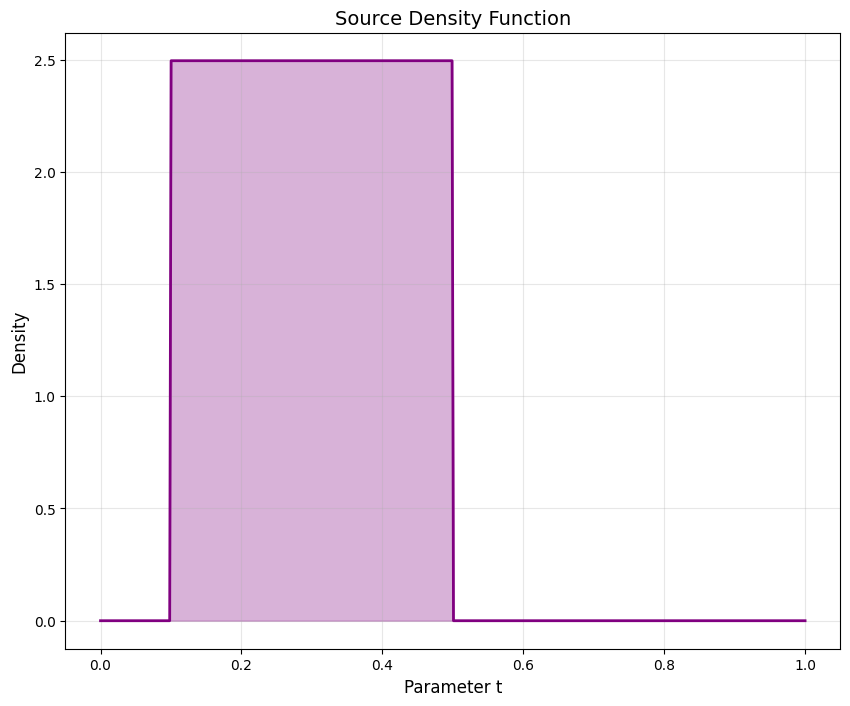

In [14]:
# Let's define a plotter and plot the initial source_density
plotter = ShapePlotter2D()
plotter.plot_source_density(shape, source_density_true, params=init_source_density)

So in total, we our posterior has 7 parameters, 5 for the ellipse (c_x,c_y,a,b, \phi) and 2 for the source-density (c,w)
There is no prior on the sha

(<Figure size 1000x800 with 1 Axes>, <Axes: >)

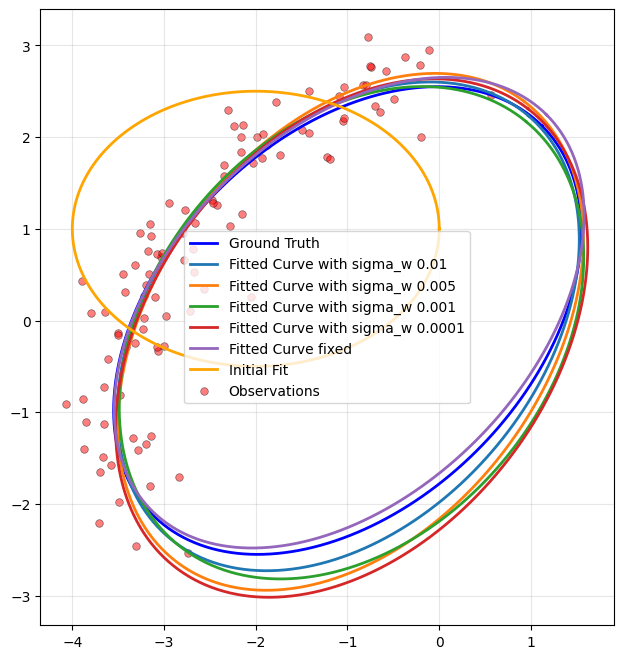

In [15]:
# we plot the result of the fit
fig, ax, _ = plotter.plot_shape(shape, theta, label="Ground Truth")
for i in range(len(results)):
    cmap = plt.get_cmap("tab10")
    color = cmap(i)
    theta_map = results[i].theta_map[0:shape.get_n_params()]
    if i == len(results) - 1: # plot the fixed one
        plotter.plot_shape(shape, theta_map, ax=ax, label="Fitted Curve fixed", color = color)   
    else: plotter.plot_shape(shape, theta_map, ax=ax, label="Fitted Curve with sigma_w " + np.array2string(covs[i][1,1]), color = color)
plotter.plot_shape(shape, init_theta, ax=ax, label="Initial Fit", color="orange")
plotter.plot_observations(observations=measurement, ax=ax)

We see, that the stonger prior we set on w (the width of the source-denstiy-interval), the closer to the ground truth the resulting fit gets, which is what we would expect.

However, we want to mention that result depends a lot on the intial fit (especially of the source-density).